# 10. 탐색적 분석(EDA)

목적: 모델에 들어가기 전에 (1) 두 지역의 기후 특성과 이벤트가 생기는 시간대, (2) 상권 구조(업종×요일, 객단가, 연령, 유동인구), (3) 이벤트일과 평상일의 매출 차이를 확인한다.
입력은 `data/processed/*.parquet`(`python code/run_all.py`로 생성). 그림은 `outputs/figures/e*.png`, 표는 `outputs/tables/e_*.csv`에 저장한다.

기준선(평상시) 정의: 각 날의 로그 매출에서 같은 요일 앞뒤 1·2주 평균을 뺀 값(편차). 공휴일·연휴 전후·추석·소비쿠폰 마지막 주 같은 특별일은 기준선에서 뺀다.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

sys.path.insert(0, str(Path.cwd()))  # code 폴더에서 실행
from common import (FIG, TAB, REGIONS, REGION_NAME, TIME_BANDS, TB_NAME, AGE_GROUPS, FACE_GROUPS, load, industry_map)
from analysis import (RC, SURFACE, INK, INK2, MUTED, GRID, AXIS, WASH, REGION_COLOR, AGE_COLOR, EVENT_COLOR,
                      exclusion_days, deviation, contrast, finish)

FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(RC)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
DIVERGE = LinearSegmentedColormap.from_list("diverge", ["#2a78d6", WASH, "#e34948"])

cal = load("calendar")
EXCL = exclusion_days(cal)
day = load("model_panel_day")
tb = load("model_panel_tb")
w = load("weather_daily").query("'2025-07-01' <= date <= '2025-12-31'").copy()
wh = load("weather_hourly").query("'2025-07-01' <= date <= '2025-12-31'").copy()
wtb = load("weather_tb").query("'2025-07-01' <= date <= '2025-12-31'").copy()
prof = load("industry_profile")
scope = day[day.in_scope == 1].copy()
face = scope[scope.group.isin(FACE_GROUPS)].copy()
tb_face = tb[(tb.in_scope == 1) & tb.group.isin(FACE_GROUPS)].copy()
print(f"분석 대상 시리즈 {scope.groupby(['region','industry']).ngroups}개, 그중 대면소비 {face.groupby(['region','industry']).ngroups}개, 제외일 {len(EXCL)}일")
summary = face.groupby("region").agg(series=("industry", "nunique"), sales_total_억=("sales", lambda s: s.sum() / 1e8),
                                     sales_day_억=("sales", lambda s: s.sum() / 1e8 / 184))
summary.round(1)

분석 대상 시리즈 141개, 그중 대면소비 101개, 제외일 24일


,series,sales_total_억,sales_day_억
region,,,
chuncheon,48,10856.4,59.0
gangnam,53,66824.3,363.2


## 1. 개요: 일 매출과 기상 이벤트

대면소비 업종(음식점·카페·소매·숙박·여가·개인서비스 등) 매출 합계. 붉은 띠는 폭염일, 푸른 띠는 영업시간에 10mm 이상 비가 온 날.

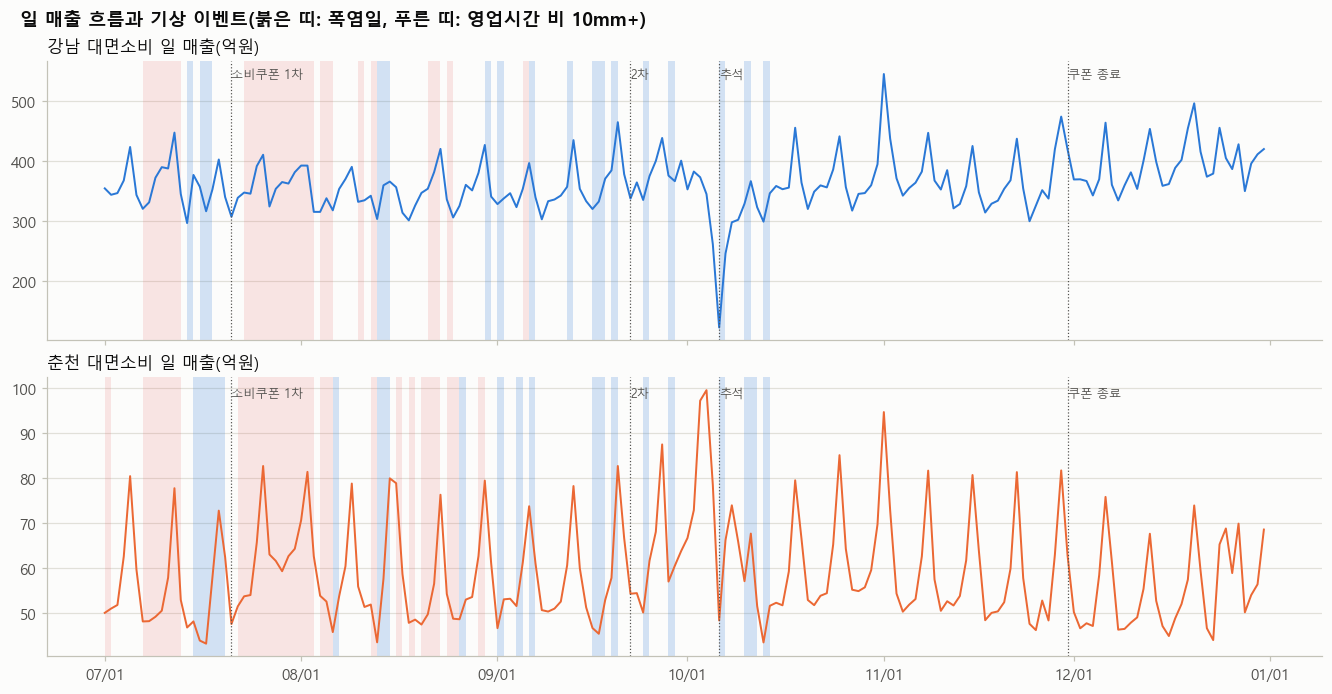

In [2]:
tot = face.groupby(["region", "date"]).sales.sum().reset_index()
fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True, layout="constrained")
for ax, r in zip(axes, REGIONS):
    t, ww = tot[tot.region == r], w[w.region == r]
    for d in ww.loc[ww.heat_day == 1, "date"]:
        ax.axvspan(d, d + pd.Timedelta(days=1), color=EVENT_COLOR["heat_day"], alpha=0.13, lw=0)
    for d in ww.loc[ww.rain_biz10 == 1, "date"]:
        ax.axvspan(d, d + pd.Timedelta(days=1), color=EVENT_COLOR["rain_biz10"], alpha=0.2, lw=0)
    ax.plot(t.date, t.sales / 1e8, color=REGION_COLOR[r], lw=1.3)
    for d, name in [("2025-07-21", "소비쿠폰 1차"), ("2025-09-22", "2차"), ("2025-10-06", "추석"), ("2025-11-30", "쿠폰 종료")]:
        ax.axvline(pd.Timestamp(d), color=INK2, lw=0.8, ls=":")
        ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.98 if ax.get_ylim()[1] > 0 else 1, name, fontsize=8, color=INK2, va="top", ha="left")
    ax.set_title(f"{REGION_NAME[r]} 대면소비 일 매출(억원)")
    ax.grid(axis="x", visible=False)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
finish(fig, FIG, "e01_overview", "일 매출 흐름과 기상 이벤트(붉은 띠: 폭염일, 푸른 띠: 영업시간 비 10mm+)")
plt.show()

## 2. 지역별 기후 특성(2025.7~12)

이벤트 정의는 `04_weather.py` 참고. 폭염일은 기상청 공식 일최고기온(서울 108·춘천 101) 33℃ 이상, 열대야는 그날 18시~다음 날 9시 최저 25℃ 이상, 호우는 영업시간(06~24시) 강수 합계 기준. 강남 강수·기온은 강남구 안 AWS(400)를 쓴다.

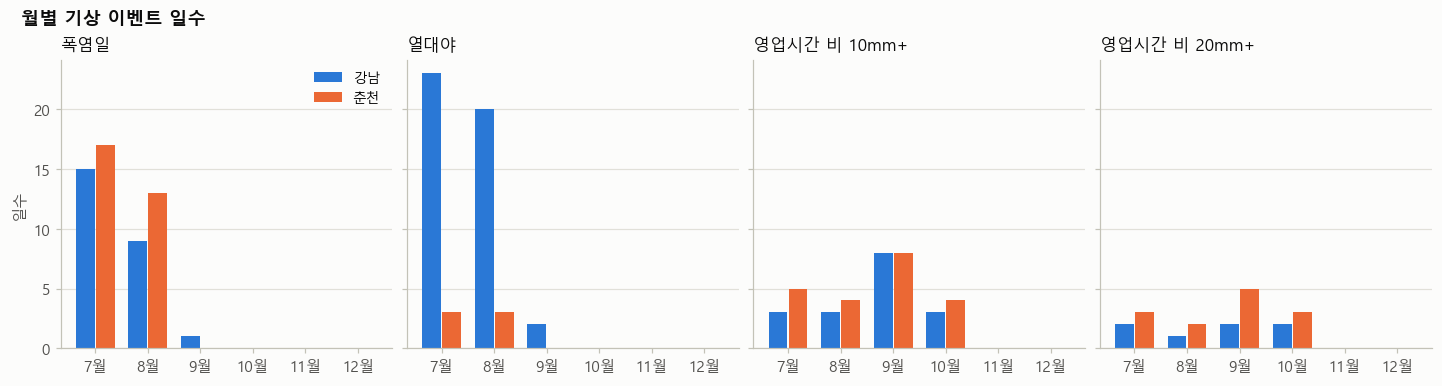

region          chuncheon  gangnam
heat_day               30       25
heat35_day             11       13
heat_feels33           19       30
tropical                6       45
rain_biz10             21       17
rain_biz20             13        7
rain_1h20               7        3
rain_adv                1        0
rain_dawn_only          0        2
cold12                  3        0


,최고기온,최고체감,밤최저최고,하루최다강수,시간최다강수,최장폭염,최장열대야,총강수
region,,,,,,,,
chuncheon,37.1,36.1,25.9,94.7,44.4,12,2,1127.4
gangnam,38.0,36.7,29.4,112.5,35.5,11,14,904.5


In [3]:
ev_cols = ["heat_day", "heat35_day", "heat_feels33", "tropical", "rain_biz10", "rain_biz20", "rain_1h20", "rain_adv", "rain_dawn_only", "cold12"]
w["month"] = w.date.dt.month
mtab = w.groupby(["region", "month"])[ev_cols].sum().astype(int)
mtab.to_csv(TAB / "e_event_days_by_month.csv", encoding="utf-8-sig")
ext = w.groupby("region").agg(최고기온=("ta_max_off", "max"), 최고체감=("feels_max", "max"), 밤최저최고=("night_min", "max"),
                             하루최다강수=("rn_sum", "max"), 시간최다강수=("rn_max_1h", "max"), 최장폭염=("heat_streak", "max"),
                             최장열대야=("tropical_streak", "max"), 총강수=("rn_sum", "sum")).round(1)
tot_ev = w.groupby("region")[ev_cols].sum().astype(int)
EV_SHOW = {"heat_day": "폭염일", "tropical": "열대야", "rain_biz10": "영업시간 비 10mm+", "rain_biz20": "영업시간 비 20mm+"}
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True, layout="constrained")
for ax, (c, name) in zip(axes, EV_SHOW.items()):
    for i, r in enumerate(REGIONS):
        v = mtab.loc[r, c].reindex(range(7, 13), fill_value=0)
        ax.bar(np.arange(6) + (i - 0.5) * 0.38, v.values, width=0.36, color=REGION_COLOR[r], label=REGION_NAME[r])
    ax.set_xticks(range(6), [f"{m}월" for m in range(7, 13)])
    ax.set_title(name)
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper right")
axes[0].set_ylabel("일수")
finish(fig, FIG, "e02_event_days", "월별 기상 이벤트 일수")
plt.show()
print(tot_ev.T)
ext

## 3. 이벤트가 자주 생기는 시간대 vs 돈이 쓰이는 시간대

회의 질문: 우리가 정한 이벤트가 어느 시간대에 자주 발생하는가. 폭염은 체감온도 33℃ 이상인 시간의 분포, 호우는 비 온 날(10mm 이상) 강수량의 시간대 분포. 같은 시간대의 카드 매출 비중과 유동인구 비중을 나란히 둔다. 이 겹침이 '노출'이다.

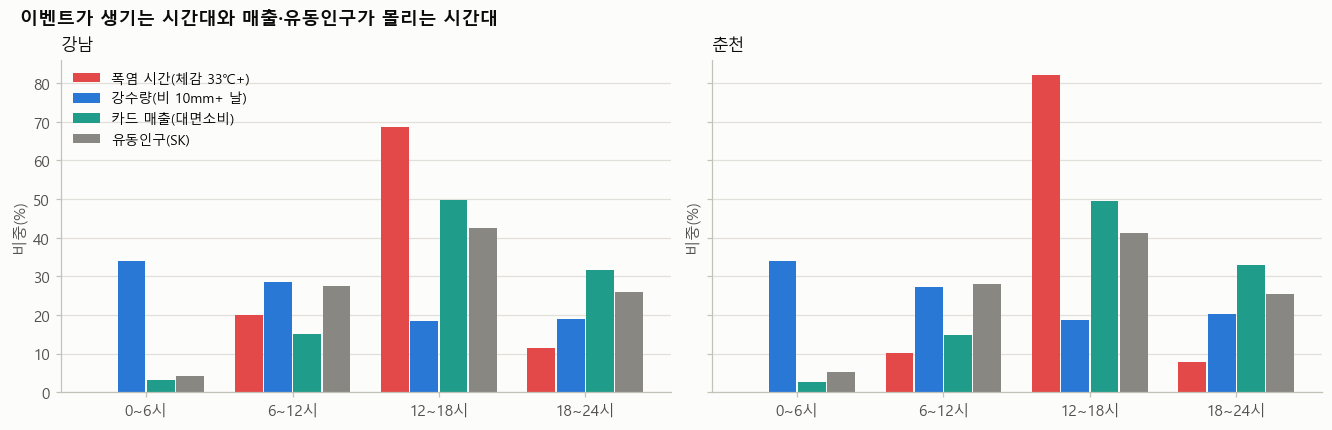

00_05  06_11  12_17  18_23
항목             region                               
폭염 시간(체감 33℃+) chuncheon    0.0   10.1   82.0    7.9
               gangnam      0.0   20.0   68.6   11.4
강수량(비 10mm+ 날) chuncheon   33.9   27.3   18.7   20.1
               gangnam     34.0   28.6   18.4   19.1
카드 매출(대면소비)    chuncheon    2.6   14.8   49.6   33.0
               gangnam      3.3   15.1   49.8   31.8
유동인구(SK)       chuncheon    5.3   28.0   41.1   25.5
               gangnam      4.2   27.6   42.4   25.8

In [4]:
TBH = {"00_05": range(0, 6), "06_11": range(6, 12), "12_17": range(12, 18), "18_23": range(18, 24)}
heat_h = wh[wh.heat_hr == 1].groupby(["region", "tb"]).size().unstack("tb").reindex(columns=TIME_BANDS, fill_value=0)
rainy = w.loc[w.rain10 == 1, ["region", "date"]]
rain_h = wh.merge(rainy, on=["region", "date"]).groupby(["region", "tb"]).rn.sum().unstack("tb").reindex(columns=TIME_BANDS, fill_value=0)
sales_tb = tb_face.groupby(["region", "tb"]).sales.sum().unstack("tb").reindex(columns=TIME_BANDS)
skp = load("sk_region_profile")
hour = skp[skp.kind == "hour"].pivot(index="region", columns="key", values="share")
sk_tb = pd.DataFrame({t: hour[[f"h{h:02d}" for h in rng]].sum(axis=1) for t, rng in TBH.items()})
share = lambda m: m.div(m.sum(axis=1), axis=0) * 100
timing = pd.concat({"폭염 시간(체감 33℃+)": share(heat_h), "강수량(비 10mm+ 날)": share(rain_h),
                    "카드 매출(대면소비)": share(sales_tb), "유동인구(SK)": share(sk_tb)}, names=["항목", "region"])
timing.round(1).to_csv(TAB / "e_timing_by_timeband.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout="constrained")
items = list(timing.index.get_level_values(0).unique())
COLS = ["#e34948", "#2a78d6", "#1f9d8a", "#898781"]
for ax, r in zip(axes, REGIONS):
    for i, (item, col) in enumerate(zip(items, COLS)):
        v = timing.loc[(item, r)].values
        ax.bar(np.arange(4) + (i - 1.5) * 0.2, v, width=0.19, color=col, label=item)
    ax.set_xticks(range(4), [TB_NAME[t] for t in TIME_BANDS])
    ax.set_title(REGION_NAME[r])
    ax.set_ylabel("비중(%)")
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left")
finish(fig, FIG, "e03_timing", "이벤트가 생기는 시간대와 매출·유동인구가 몰리는 시간대")
plt.show()
timing.round(1)

## 4. 유동인구 구조(SK): 누가 언제 밖에 있나

SK 자료는 월별 일평균이라 날씨 효과를 재는 데는 못 쓰고, 지역의 노출 구조(시간대·요일·연령)로만 쓴다.

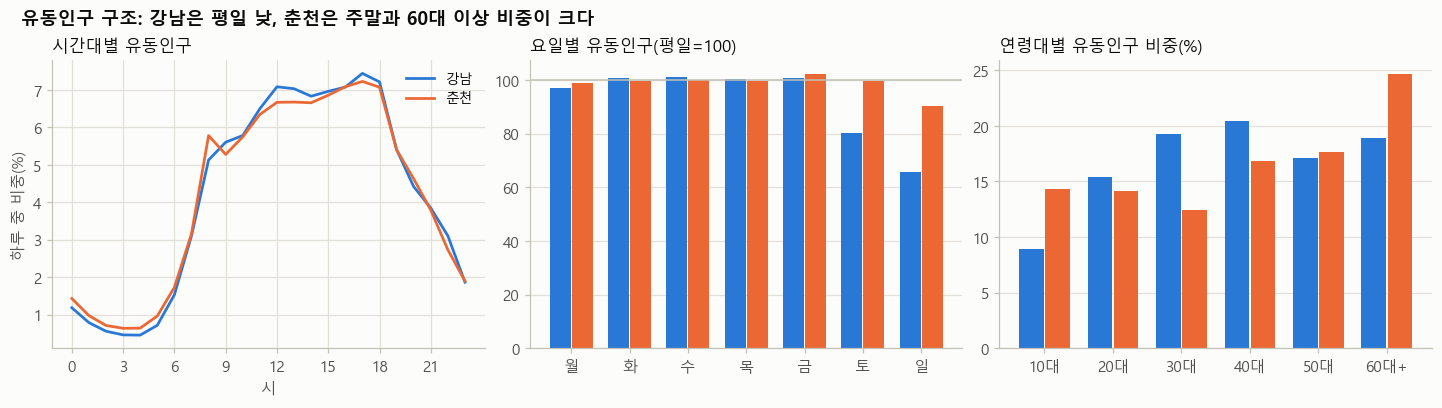

유동인구 60대+ 비중(%) {'chuncheon': 24.7, 'gangnam': 18.9}
카드 매출 연령 구성(%)


,10-20대,30-50대,60대+
region,,,
chuncheon,11.2,68.0,20.8
gangnam,11.3,73.1,15.6


In [5]:
age_p = skp[skp.kind == "age"].pivot(index="region", columns="key", values="share")
wk_p = skp[skp.kind == "wkdy"].pivot(index="region", columns="key", values="value")
wk_idx = wk_p.div(wk_p[["mon", "tue", "wed", "thu", "fri"]].mean(axis=1), axis=0) * 100
age_tot = pd.DataFrame({a: age_p[f"m{a}"] + age_p[f"f{a}"] for a in ["10", "20", "30", "40", "50", "60"]}) * 100
card_age = prof[prof.group.isin(FACE_GROUPS) & (prof.coverage >= 0.95)].groupby("region").apply(
    lambda g: pd.Series({a: np.average(g[f"share_age_{a}"], weights=g.sales_total) for a in AGE_GROUPS}), include_groups=False) * 100
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout="constrained")
for r in REGIONS:
    axes[0].plot(range(24), hour.loc[r, [f"h{h:02d}" for h in range(24)]].values * 100, color=REGION_COLOR[r], lw=1.8, label=REGION_NAME[r])
axes[0].set_xticks(range(0, 24, 3)); axes[0].set_xlabel("시"); axes[0].set_ylabel("하루 중 비중(%)"); axes[0].set_title("시간대별 유동인구"); axes[0].legend()
for i, r in enumerate(REGIONS):
    axes[1].bar(np.arange(7) + (i - 0.5) * 0.38, wk_idx.loc[r, ["mon", "tue", "wed", "thu", "fri", "sat", "sun"]].values, width=0.36, color=REGION_COLOR[r])
axes[1].axhline(100, color=AXIS, lw=1); axes[1].set_xticks(range(7), list("월화수목금토일")); axes[1].set_title("요일별 유동인구(평일=100)"); axes[1].grid(axis="x", visible=False)
for i, r in enumerate(REGIONS):
    axes[2].bar(np.arange(6) + (i - 0.5) * 0.38, age_tot.loc[r].values, width=0.36, color=REGION_COLOR[r])
axes[2].set_xticks(range(6), ["10대", "20대", "30대", "40대", "50대", "60대+"]); axes[2].set_title("연령대별 유동인구 비중(%)"); axes[2].grid(axis="x", visible=False)
finish(fig, FIG, "e04_sk_structure", "유동인구 구조: 강남은 평일 낮, 춘천은 주말과 60대 이상 비중이 크다")
plt.show()
print("유동인구 60대+ 비중(%)", age_tot["60"].round(1).to_dict())
print("카드 매출 연령 구성(%)"); card_age.round(1)

## 5. 업종 × 요일 매출(회의 항목)

특별일을 뺀 요일 평균 매출을 평일 평균=100으로 지수화. 주말에 매출이 몰리는 업종은 주말 비가 더 아프다(한국은행 이슈노트: 금·토 비 효과가 더 큼).

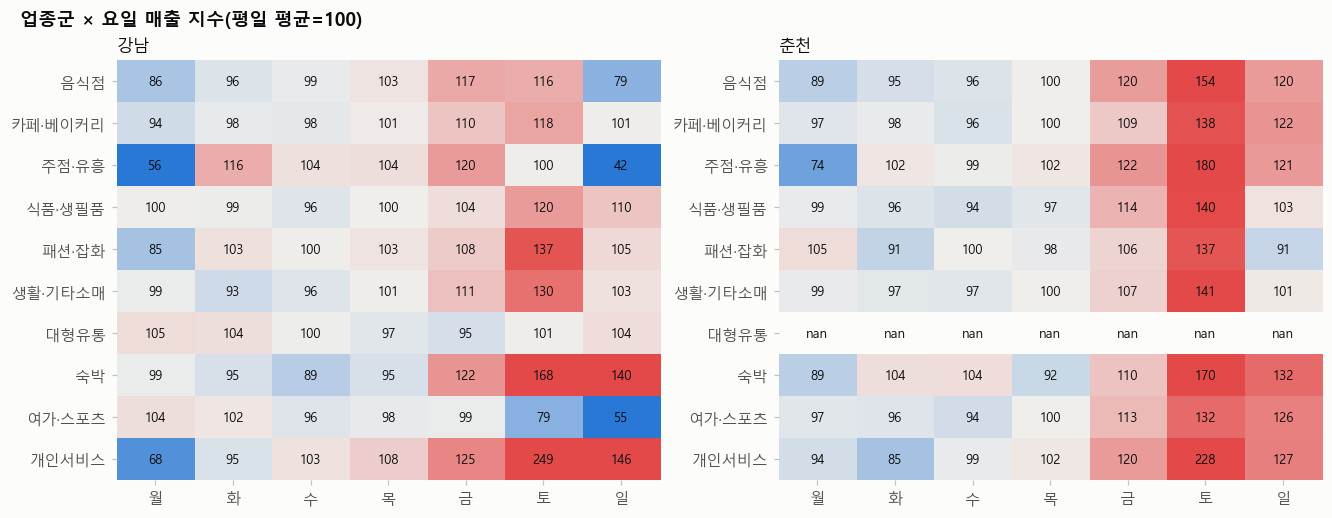

region  chuncheon                                           gangnam                                          
dow             0      1      2      3      4      5      6       0      1      2      3      4      5      6
group                                                                                                        
음식점          89.0   95.0   96.0  100.0  120.0  154.0  120.0    86.0   96.0   99.0  103.0  117.0  116.0   79.0
카페·베이커리      97.0   98.0   96.0  100.0  109.0  138.0  122.0    94.0   98.0   98.0  101.0  110.0  118.0  101.0
주점·유흥        74.0  102.0   99.0  102.0  122.0  180.0  121.0    56.0  116.0  104.0  104.0  120.0  100.0   42.0
식품·생필품       99.0   96.0   94.0   97.0  114.0  140.0  103.0   100.0   99.0   96.0  100.0  104.0  120.0  110.0
패션·잡화       105.0   91.0  100.0   98.0  106.0  137.0   91.0    85.0  103.0  100.0  103.0  108.0  137.0  105.0
생활·기타소매      99.0   97.0   97.0  100.0  107.0  141.0  101.0    99.0   93.0   96.0  101.0  111.0  130.0  103.0
대형유통          NaN    NaN    NaN    NaN    NaN    NaN    NaN   105.0  104.0  100.0   97.0   95.0  101.0  104.0
숙박           89.0  104.0  104.0   92.0  110.0  170.0  132.0    99.0   95.0   89.0   95.0  122.0  168.0  140.0
여가·스포츠       97.0   96.0   94.0  100.0  113.0  132.0  126.0   104.0  102.0   96.0   98.0   99.0   79.0   55.0
개인서비스        94.0   85.0   99.0  102.0  120.0  228.0  127.0    68.0   95.0  103.0  108.0  125.0  249.0  146.0

In [6]:
ok = face[~face.date.isin(EXCL)]
d = ok.groupby(["region", "group", "dow", "date"]).sales.sum().groupby(["region", "group", "dow"]).mean().reset_index()
d = d.join(d[d.dow < 5].groupby(["region", "group"]).sales.mean().rename("wk"), on=["region", "group"])
d["idx"] = d.sales / d.wk * 100
piv = d.pivot_table(index="group", columns=["region", "dow"], values="idx").loc[FACE_GROUPS]
piv.round(0).to_csv(TAB / "e_weekday_index.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
norm = TwoSlopeNorm(vmin=60, vcenter=100, vmax=140)
for ax, r in zip(axes, REGIONS):
    m = piv[r]
    ax.imshow(m.values, cmap=DIVERGE, norm=norm, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.values[i, j]:.0f}", ha="center", va="center", fontsize=8.5, color=INK)
    ax.set_xticks(range(7), list("월화수목금토일")); ax.set_yticks(range(len(m)), m.index)
    ax.set_title(REGION_NAME[r]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
finish(fig, FIG, "e05_weekday", "업종군 × 요일 매출 지수(평일 평균=100)")
plt.show()
piv.round(0)

## 6. 객단가와 연령대별 소비(회의 항목)

객단가 = 결제금액 / 결제건수. 연령대별로 어느 업종을 얼마나 자주(건수 비중), 얼마나 크게(객단가) 쓰는지 본다.

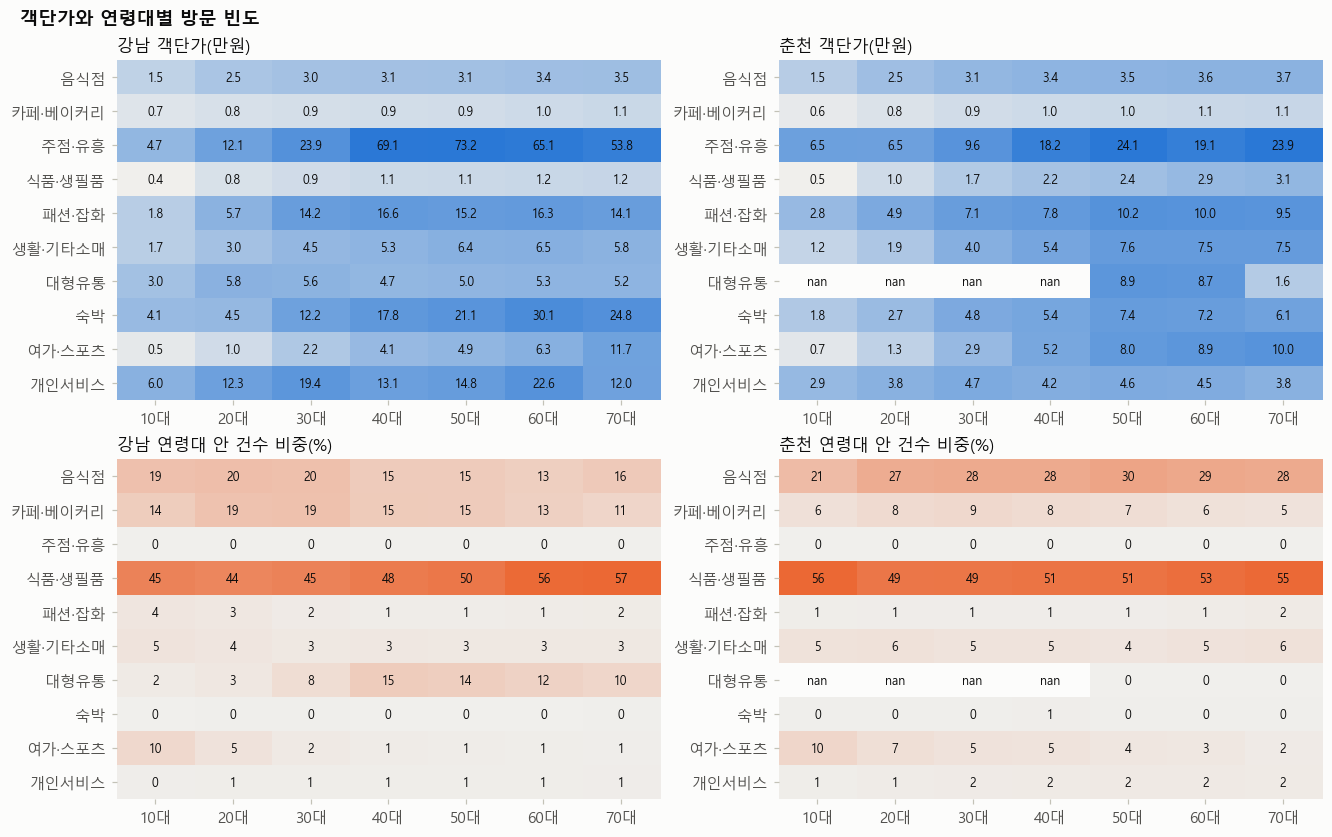

region,chuncheon,gangnam
group,,
음식점,3.18,2.98
카페·베이커리,0.95,0.88
주점·유흥,15.13,40.13
식품·생필품,1.99,1.02
패션·잡화,8.08,12.12
생활·기타소매,4.96,4.93
대형유통,7.69,5.07
숙박,5.47,15.42
여가·스포츠,4.21,2.56


In [7]:
c1 = load("card1_clean")
c1 = c1[c1.sex != "CORP"].merge(industry_map()[["industry", "group"]], on="industry")
c1 = c1[c1.group.isin(FACE_GROUPS)]
t_grp = c1.groupby(["region", "group"]).agg(sales=("sales", "sum"), cnt=("cnt", "sum"))
t_grp["ticket"] = t_grp.sales / t_grp.cnt
t_age = c1.groupby(["region", "group", "age"]).agg(sales=("sales", "sum"), cnt=("cnt", "sum"))
t_age["ticket"] = t_age.sales / t_age.cnt
cnt_share = (t_age.cnt / t_age.groupby(["region", "age"]).cnt.transform("sum") * 100)  # 연령대 안에서 업종군별 건수 비중(방문 빈도)
tk = t_age.ticket.unstack("age") / 1e4
cs = cnt_share.unstack("age")
pd.concat({"객단가_만원": tk.round(2), "건수비중_%": cs.round(1)}).to_csv(TAB / "e_ticket_age.csv", encoding="utf-8-sig")
AGES = [10, 20, 30, 40, 50, 60, 70, 80, 90]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained")
for j, r in enumerate(REGIONS):
    m = tk.loc[r].reindex(FACE_GROUPS).reindex(columns=AGES[:7])
    ax = axes[0, j]
    ax.imshow(np.log(m.values), cmap=LinearSegmentedColormap.from_list("seq", [WASH, "#2a78d6"]), aspect="auto")
    for i in range(m.shape[0]):
        for k in range(m.shape[1]):
            ax.text(k, i, f"{m.values[i, k]:.1f}", ha="center", va="center", fontsize=8, color=INK)
    ax.set_xticks(range(7), [f"{a}대" for a in AGES[:7]]); ax.set_yticks(range(len(m)), m.index); ax.set_title(f"{REGION_NAME[r]} 객단가(만원)"); ax.grid(False)
    m2 = cs.loc[r].reindex(FACE_GROUPS).reindex(columns=AGES[:7])
    ax = axes[1, j]
    ax.imshow(m2.values, cmap=LinearSegmentedColormap.from_list("seq2", [WASH, "#eb6834"]), aspect="auto")
    for i in range(m2.shape[0]):
        for k in range(m2.shape[1]):
            ax.text(k, i, f"{m2.values[i, k]:.0f}", ha="center", va="center", fontsize=8, color=INK)
    ax.set_xticks(range(7), [f"{a}대" for a in AGES[:7]]); ax.set_yticks(range(len(m2)), m2.index); ax.set_title(f"{REGION_NAME[r]} 연령대 안 건수 비중(%)"); ax.grid(False)
for ax in axes.flat:
    for sp in ax.spines.values(): sp.set_visible(False)
finish(fig, FIG, "e06_ticket_age", "객단가와 연령대별 방문 빈도")
plt.show()
(t_grp.ticket / 1e4).unstack("region").loc[FACE_GROUPS].round(2)

## 7. 교란 요인: 민생회복 소비쿠폰

쿠폰(7/21 1차, 9/22 2차, 11/30 종료)은 연매출 30억 이하 소상공인 가맹점에서만 쓸 수 있다. 소상공인 중심 업종과 그 외 업종의 주별 매출 지수를 비교한다.

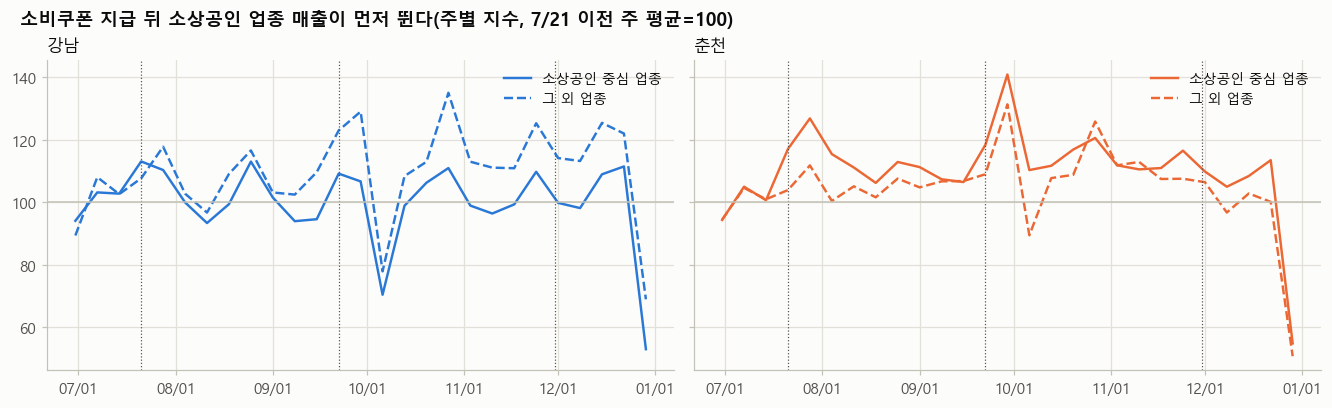

In [8]:
wk = scope.copy()
wk["week_start"] = wk.date - pd.to_timedelta(wk.dow, unit="D")
g = wk.groupby(["region", "small_biz", "week_start"]).sales.sum().reset_index()
base = g[g.week_start < "2025-07-21"].groupby(["region", "small_biz"]).sales.mean().rename("base")
g = g.join(base, on=["region", "small_biz"]); g["idx"] = g.sales / g.base * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True, layout="constrained")
for ax, r in zip(axes, REGIONS):
    for sb, ls, lab in [(1, "-", "소상공인 중심 업종"), (0, "--", "그 외 업종")]:
        x = g[(g.region == r) & (g.small_biz == sb)]
        ax.plot(x.week_start, x.idx, color=REGION_COLOR[r], ls=ls, lw=1.6, label=lab)
    for d in ["2025-07-21", "2025-09-22", "2025-11-30"]:
        ax.axvline(pd.Timestamp(d), color=INK2, lw=0.8, ls=":")
    ax.axhline(100, color=AXIS, lw=1)
    ax.set_title(REGION_NAME[r]); ax.legend(loc="upper right")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
finish(fig, FIG, "e07_coupon", "소비쿠폰 지급 뒤 소상공인 업종 매출이 먼저 뛴다(주별 지수, 7/21 이전 주 평균=100)")
plt.show()

## 8. 이벤트일 vs 평상일: 1차 비교

편차(로그 매출 − 같은 요일 앞뒤 2주 평균)를 이벤트 조건별로 평균해 비교한다. 비는 '비 없는 날(영업시간 강수 1mm 미만)' 대비, 폭염·열대야는 '7~9월 비 없는 날 중 이벤트가 아닌 날' 대비.

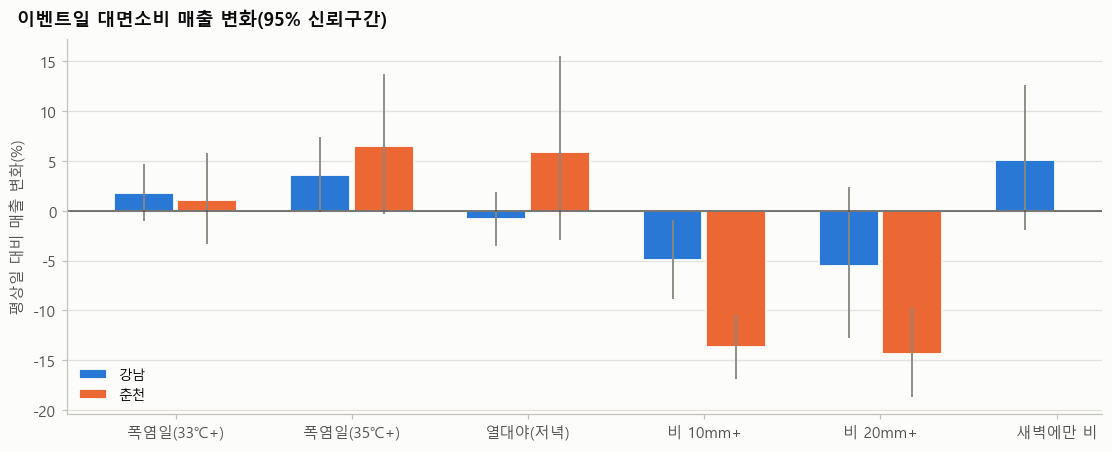

pct    lo    hi     n
이벤트       region                           
폭염일(33℃+) chuncheon   1.1  -3.4   5.8  28.0
          gangnam     1.8  -1.0   4.7  25.0
폭염일(35℃+) chuncheon   6.5  -0.3  13.8  11.0
          gangnam     3.6  -0.1   7.4  13.0
열대야(저녁)   chuncheon   5.9  -3.0  15.6   6.0
          gangnam    -0.9  -3.6   1.9  40.0
비 10mm+   chuncheon -13.7 -16.9 -10.4  18.0
          gangnam    -5.0  -8.8  -1.0  14.0
비 20mm+   chuncheon -14.4 -18.7  -9.8  11.0
          gangnam    -5.5 -12.8   2.4   5.0
새벽에만 비    chuncheon   NaN   NaN   NaN   NaN
          gangnam     5.1  -2.0  12.7   2.0

In [9]:
WCOLS = ["region", "date", "heat_day", "tropical", "rain_biz10", "rain_biz20", "rn_biz", "rain_dawn_only", "feels_max", "cold12", "heat35_day"]
W = w[WCOLS]
fd = deviation(face, ["region"], excl=EXCL).merge(W, on=["region", "date"])
dry, summer = fd.rn_biz < 1, fd.date.dt.month.between(7, 9)
tests = {
    "폭염일(33℃+)": ((fd.heat_day == 1) & dry, (fd.heat_day == 0) & dry & summer),
    "폭염일(35℃+)": ((fd.heat35_day == 1) & dry, (fd.heat_day == 0) & dry & summer),
    "열대야(저녁)": ((fd.tropical == 1) & dry, (fd.tropical == 0) & dry & summer),
    "비 10mm+": (fd.rain_biz10 == 1, dry),
    "비 20mm+": (fd.rain_biz20 == 1, dry),
    "새벽에만 비": (fd.rain_dawn_only == 1, dry),
}
R = pd.concat({k: contrast(fd, ["region"], a, b) for k, (a, b) in tests.items()}, names=["이벤트", "region"])
R.round(1).to_csv(TAB / "e_event_contrast_region.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
names = list(tests)
for i, r in enumerate(REGIONS):
    x = R.xs(r, level="region").reindex(names)
    pos = np.arange(len(names)) + (i - 0.5) * 0.36
    ax.bar(pos, x.pct, width=0.34, color=REGION_COLOR[r], label=REGION_NAME[r], edgecolor=SURFACE, linewidth=1.2)
    ax.errorbar(pos, x.pct, yerr=np.vstack([x.pct - x.lo, x.hi - x.pct]), fmt="none", ecolor=MUTED, elinewidth=1.2, capsize=0)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(len(names)), names)
ax.set_ylabel("평상일 대비 매출 변화(%)")
ax.legend(loc="lower left")
ax.grid(axis="x", visible=False)
finish(fig, FIG, "e08_event_contrast", "이벤트일 대면소비 매출 변화(95% 신뢰구간)")
plt.show()
R[["pct", "lo", "hi", "n"]].round(1)

업종군별로 나눠 본다(열: 이벤트, 값: 평상일 대비 %).

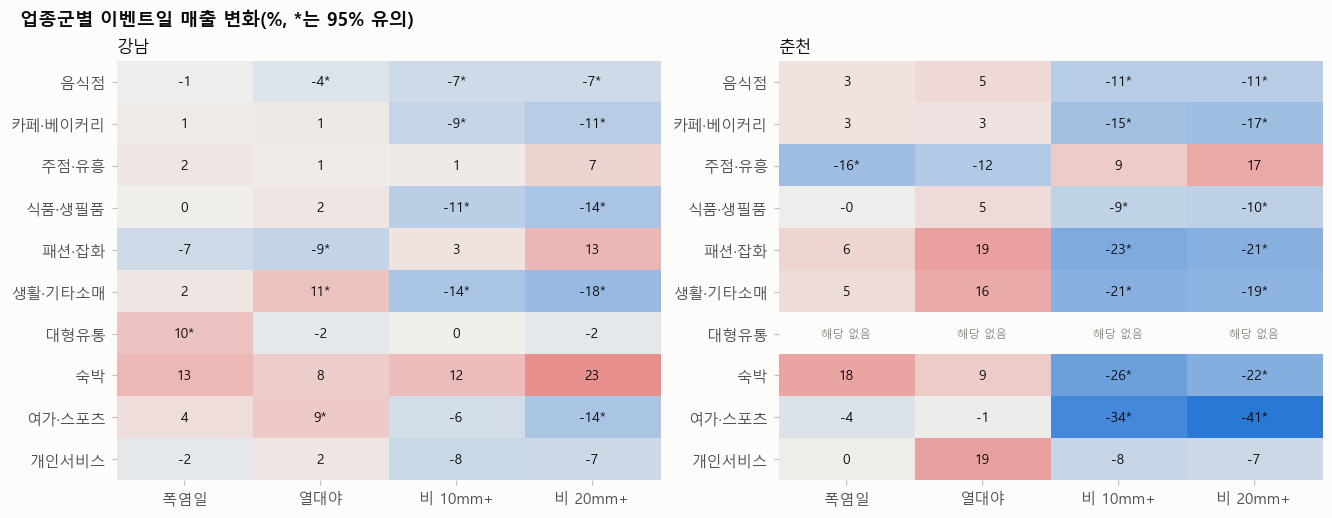

이벤트                 폭염일   열대야  비 10mm+  비 20mm+
region    group                                
gangnam   음식점      -1.0  -4.0     -7.0     -7.0
          카페·베이커리   1.0   1.0     -9.0    -11.0
          주점·유흥     2.0   1.0      1.0      7.0
          식품·생필품    0.0   2.0    -11.0    -14.0
          패션·잡화    -7.0  -9.0      3.0     13.0
          생활·기타소매   2.0  11.0    -14.0    -18.0
          대형유통     10.0  -2.0      0.0     -2.0
          숙박       13.0   8.0     12.0     23.0
          여가·스포츠    4.0   9.0     -6.0    -14.0
          개인서비스    -2.0   2.0     -8.0     -7.0
chuncheon 음식점       3.0   5.0    -11.0    -11.0
          카페·베이커리   3.0   3.0    -15.0    -17.0
          주점·유흥   -16.0 -12.0      9.0     17.0
          식품·생필품   -0.0   5.0     -9.0    -10.0
          패션·잡화     6.0  19.0    -23.0    -21.0
          생활·기타소매   5.0  16.0    -21.0    -19.0
          대형유통      NaN   NaN      NaN      NaN
          숙박       18.0   9.0    -26.0    -22.0
          여가·스포츠   -4.0  -1.0    -34.0    -41.0
          개인서비스     0.0  19.0     -8.0     -7.0

In [10]:
fg = deviation(face, ["region", "group"], excl=EXCL).merge(W, on=["region", "date"])
dry, summer = fg.rn_biz < 1, fg.date.dt.month.between(7, 9)
tests_g = {"폭염일": ((fg.heat_day == 1) & dry, (fg.heat_day == 0) & dry & summer),
           "열대야": ((fg.tropical == 1) & dry, (fg.tropical == 0) & dry & summer),
           "비 10mm+": (fg.rain_biz10 == 1, dry), "비 20mm+": (fg.rain_biz20 == 1, dry)}
RG = pd.concat({k: contrast(fg, ["region", "group"], a, b) for k, (a, b) in tests_g.items()}, names=["이벤트", "region", "group"])
RG.round(1).to_csv(TAB / "e_event_contrast_group.csv", encoding="utf-8-sig")
idx = pd.MultiIndex.from_product([REGIONS, FACE_GROUPS], names=["region", "group"])
pm = RG.pct.unstack("이벤트").reindex(idx)
zm = RG.z.unstack("이벤트").reindex(idx)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
norm = TwoSlopeNorm(vmin=-40, vcenter=0, vmax=40)
for ax, r in zip(axes, REGIONS):
    m = pm.loc[r][list(tests_g)]
    ax.imshow(np.ma.masked_invalid(m.values), cmap=DIVERGE, norm=norm, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v, z = m.values[i, j], zm.loc[(r, m.index[i]), m.columns[j]]
            if np.isnan(v):
                ax.text(j, i, "해당 없음", ha="center", va="center", fontsize=7.5, color=MUTED)
            else:
                ax.text(j, i, f"{v:.0f}" + ("*" if abs(z) >= 1.96 else ""), ha="center", va="center", fontsize=9, color=INK)
    ax.set_xticks(range(m.shape[1]), m.columns); ax.set_yticks(range(len(m)), m.index); ax.set_title(REGION_NAME[r]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
finish(fig, FIG, "e09_event_group", "업종군별 이벤트일 매출 변화(%, *는 95% 유의)")
plt.show()
pm.round(0)

## 9. 비가 온 시간대의 매출

같은 날이라도 비가 온 시간대의 매출만 줄어드는지 본다(시간대별 편차, 그 시간대에 1mm 이상 비 vs 비 없는 날).

C:\Users\nk233\Desktop\YBIGTA\26-2학기\학기중\빅콘\code\analysis.py:56: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  a = df[cond_a].groupby(keys)[col].agg(["mean", "var", "count"])
C:\Users\nk233\Desktop\YBIGTA\26-2학기\학기중\빅콘\code\analysis.py:57: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  b = df[cond_b].groupby(keys)[col].agg(["mean", "var", "count"])


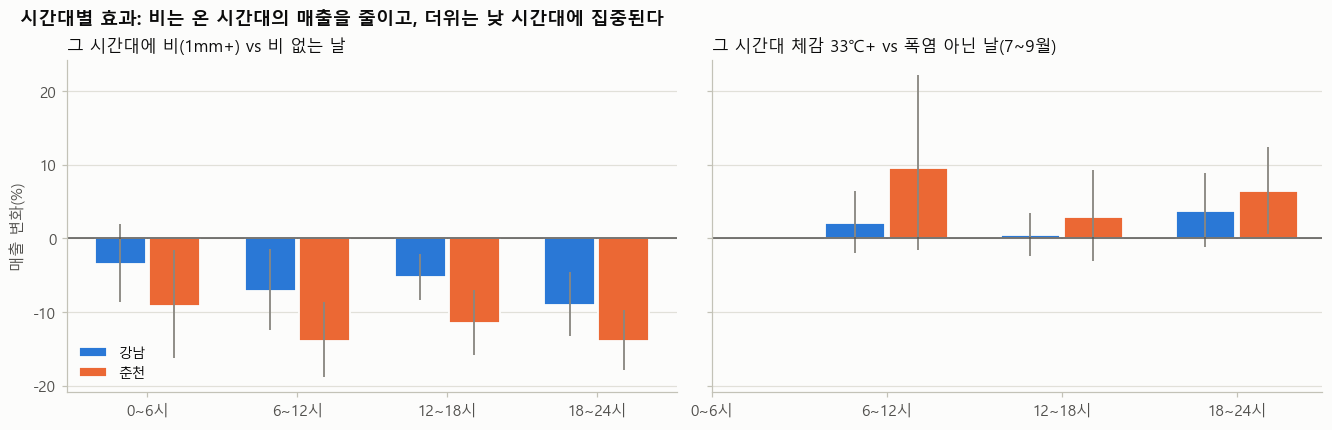

pct    lo    hi     n
   region    tb                           
비  chuncheon 00_05  -9.2 -16.2  -1.5  20.0
             06_11 -13.9 -18.9  -8.7  20.0
             12_17 -11.5 -15.8  -7.0  18.0
             18_23 -13.9 -17.9  -9.8  20.0
   gangnam   00_05  -3.5  -8.6   1.9  19.0
             06_11  -7.2 -12.5  -1.5  16.0
             12_17  -5.3  -8.4  -2.1  16.0
             18_23  -9.0 -13.3  -4.6  19.0
더위 chuncheon 00_05   NaN   NaN   NaN   NaN
             06_11   9.6  -1.6  22.1   7.0
             12_17   2.9  -3.1   9.3  18.0
             18_23   6.4   0.6  12.4   7.0
   gangnam   00_05   NaN   NaN   NaN   NaN
             06_11   2.1  -2.0   6.4  14.0
             12_17   0.5  -2.4   3.4  27.0
             18_23   3.7  -1.2   8.8   9.0

In [11]:
td = deviation(tb_face, ["region", "tb"], excl=EXCL)
td = td.merge(wtb[["region", "date", "tb", "rn_sum", "heat"]], on=["region", "date", "tb"])
td = td.merge(w[["region", "date", "rn_biz", "heat_day"]], on=["region", "date"])
res_tb = contrast(td, ["region", "tb"], td.rn_sum >= 1, td.rn_biz < 1)
res_tb_h = contrast(td[td.date.dt.month.between(7, 9) & (td.rn_biz < 1)], ["region", "tb"],
                    td.heat == 1, td.heat_day == 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout="constrained")
for ax, (res, ttl) in zip(axes, [(res_tb, "그 시간대에 비(1mm+) vs 비 없는 날"), (res_tb_h, "그 시간대 체감 33℃+ vs 폭염 아닌 날(7~9월)")]):
    for i, r in enumerate(REGIONS):
        x = res.xs(r, level="region").reindex(TIME_BANDS)
        pos = np.arange(4) + (i - 0.5) * 0.36
        ax.bar(pos, x.pct, width=0.34, color=REGION_COLOR[r], label=REGION_NAME[r], edgecolor=SURFACE, linewidth=1.2)
        ax.errorbar(pos, x.pct, yerr=np.vstack([x.pct - x.lo, x.hi - x.pct]), fmt="none", ecolor=MUTED, elinewidth=1.2)
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(4), [TB_NAME[t] for t in TIME_BANDS]); ax.set_title(ttl); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("매출 변화(%)"); axes[0].legend(loc="lower left")
finish(fig, FIG, "e10_timeband", "시간대별 효과: 비는 온 시간대의 매출을 줄이고, 더위는 낮 시간대에 집중된다")
plt.show()
pd.concat({"비": res_tb, "더위": res_tb_h})[["pct", "lo", "hi", "n"]].round(1)

## 10. 연령대별 반응(회의 항목: 폭염에 고령층이 밖에 나오기 힘든가)

연령군별 결제액 편차. 폭염은 대면소비 전체 편차를 뺀 상대값으로 본다(연령군 간 차이만 남긴다).

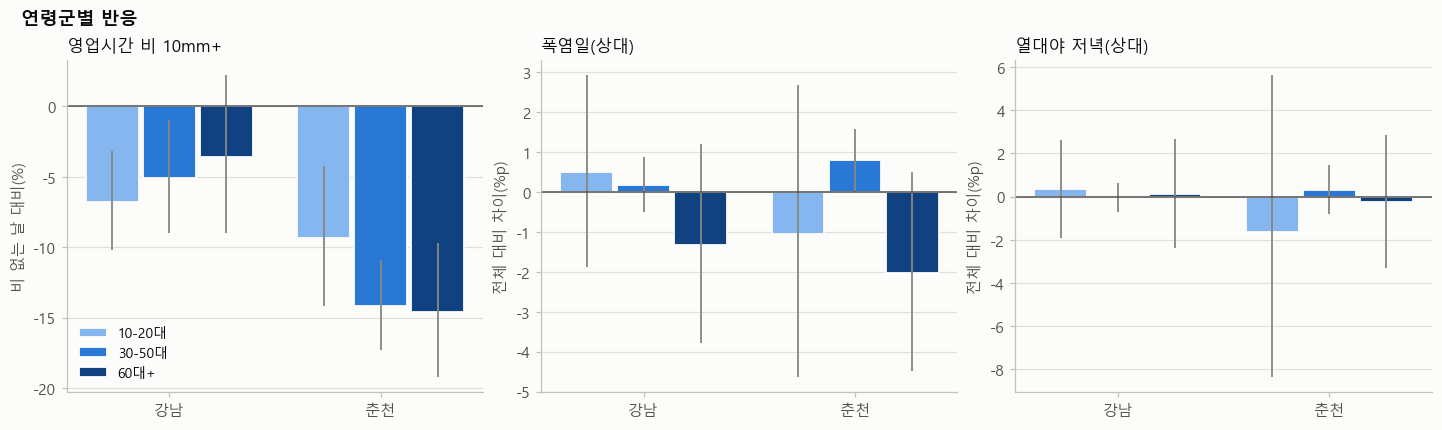

pct    lo    hi
        region    age_group                  
비       chuncheon 10-20대     -9.3 -14.1  -4.2
                  30-50대    -14.2 -17.3 -10.9
                  60대+      -14.6 -19.2  -9.7
        gangnam   10-20대     -6.8 -10.2  -3.2
                  30-50대     -5.1  -9.0  -0.9
                  60대+       -3.6  -9.0   2.2
폭염(상대)  chuncheon 10-20대     -1.0  -4.6   2.7
                  30-50대      0.8   0.0   1.6
                  60대+       -2.0  -4.5   0.5
        gangnam   10-20대      0.5  -1.9   2.9
                  30-50대      0.2  -0.5   0.9
                  60대+       -1.3  -3.8   1.2
열대야(상대) chuncheon 10-20대     -1.6  -8.4   5.6
                  30-50대      0.3  -0.8   1.5
                  60대+       -0.3  -3.3   2.8
        gangnam   10-20대      0.3  -1.9   2.6
                  30-50대     -0.0  -0.7   0.6
                  60대+        0.1  -2.4   2.6

In [12]:
ag = load("card_day_age").merge(face[["region", "industry"]].drop_duplicates(), on=["region", "industry"])
ad = deviation(ag, ["region", "age_group"], excl=EXCL).merge(W, on=["region", "date"])
ad = ad.merge(deviation(face, ["region"], excl=EXCL).rename(columns={"dev": "dev_all"}), on=["region", "date"])
ad["rel"] = ad.dev - ad.dev_all
dry, summer = ad.rn_biz < 1, ad.date.dt.month.between(7, 9)
res_ar = contrast(ad, ["region", "age_group"], ad.rain_biz10 == 1, dry)
res_ah = contrast(ad, ["region", "age_group"], (ad.heat_day == 1) & dry, (ad.heat_day == 0) & dry & summer, col="rel")
res_at = contrast(ad, ["region", "age_group"], (ad.tropical == 1) & dry, (ad.tropical == 0) & dry & summer, col="rel")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, (res, ttl, yl) in zip(axes, [(res_ar, "영업시간 비 10mm+", "비 없는 날 대비(%)"), (res_ah, "폭염일(상대)", "전체 대비 차이(%p)"), (res_at, "열대야 저녁(상대)", "전체 대비 차이(%p)")]):
    for i, a in enumerate(AGE_GROUPS):
        x = res.xs(a, level="age_group").reindex(REGIONS)
        pos = np.arange(2) + (i - 1) * 0.27
        ax.bar(pos, x.pct, width=0.25, color=AGE_COLOR[a], label=a, edgecolor=SURFACE, linewidth=1.2)
        ax.errorbar(pos, x.pct, yerr=np.vstack([x.pct - x.lo, x.hi - x.pct]), fmt="none", ecolor=MUTED, elinewidth=1.2)
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(2), [REGION_NAME[r] for r in REGIONS]); ax.set_title(ttl); ax.set_ylabel(yl); ax.grid(axis="x", visible=False)
axes[0].legend(loc="lower left")
finish(fig, FIG, "e11_age", "연령군별 반응")
plt.show()
pd.concat({"비": res_ar, "폭염(상대)": res_ah, "열대야(상대)": res_at})[["pct", "lo", "hi"]].round(1)

## 11. 요약표

In [13]:
out = {}
for r in REGIONS:
    out[r] = {"폭염일": int(tot_ev.loc[r, "heat_day"]), "열대야": int(tot_ev.loc[r, "tropical"]),
              "비10mm+일": int(tot_ev.loc[r, "rain_biz10"]), "비20mm+일": int(tot_ev.loc[r, "rain_biz20"]),
              "폭염 효과%": R.loc[("폭염일(33℃+)", r), "pct"], "열대야 효과%": R.loc[("열대야(저녁)", r), "pct"],
              "비10 효과%": R.loc[("비 10mm+", r), "pct"], "비20 효과%": R.loc[("비 20mm+", r), "pct"],
              "낮시간 비 효과%": res_tb.loc[(r, "12_17"), "pct"], "저녁 비 효과%": res_tb.loc[(r, "18_23"), "pct"]}
summ = pd.DataFrame(out).T.round(1)
summ.to_csv(TAB / "e_summary.csv", encoding="utf-8-sig")
summ

,폭염일,열대야,비10mm+일,비20mm+일,폭염 효과%,열대야 효과%,비10 효과%,비20 효과%,낮시간 비 효과%,저녁 비 효과%
gangnam,25.0,45.0,17.0,7.0,1.8,-0.9,-5.0,-5.5,-5.3,-9.0
chuncheon,30.0,6.0,21.0,13.0,1.1,5.9,-13.7,-14.4,-11.5,-13.9
